# Model 1 · 1. EDA dataset deteksi jerawat


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

SET = [('deteksi', 'train'), ('deteksi', 'valid'), ('deteksi', 'test'), ('deteksi_bh', 'train'), ('deteksi_bh', 'test')]


def baca_label(p):
    if not p.exists():
        return []
    return [list(map(float, t.split()[1:5])) for t in p.read_text().splitlines() if len(t.split()) >= 5]


rows, kotak = [], []
for d, s in SET:
    for g in sorted((DATA / d / s / 'images').glob('*')):
        W, H = Image.open(g).size
        lb = baca_label(DATA / d / s / 'labels' / (g.stem + '.txt'))
        rows.append({'dataset': d, 'bagian': s, 'foto': g, 'lebar': W, 'tinggi': H, 'kotak': len(lb)})
        for x, y, w, h in lb:
            kotak.append({'dataset': d, 'bagian': s, 'w_px': w * W, 'h_px': h * H, 'luas_rel': w * h})
foto, kotak = pd.DataFrame(rows), pd.DataFrame(kotak)
print('total foto:', len(foto), '| total kotak:', len(kotak))

folder proyek: c:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


total foto: 2427 | total kotak: 28025


## 1. Jumlah foto dan kotak

In [2]:
ring = foto.groupby(['dataset', 'bagian'], sort=False).agg(foto=('foto', 'count'), kotak=('kotak', 'sum'),
                                                         kotak_per_foto=('kotak', 'mean'), tanpa_kotak=('kotak', lambda k: (k == 0).sum()))
print(ring.round(1).to_string())

                   foto  kotak  kotak_per_foto  tanpa_kotak
dataset    bagian                                          
deteksi    train   1781  18909            10.6           12
           valid     56    643            11.5            0
           test      48    607            12.6            0
deteksi_bh train    434   6640            15.3            0
           test     108   1226            11.4            0


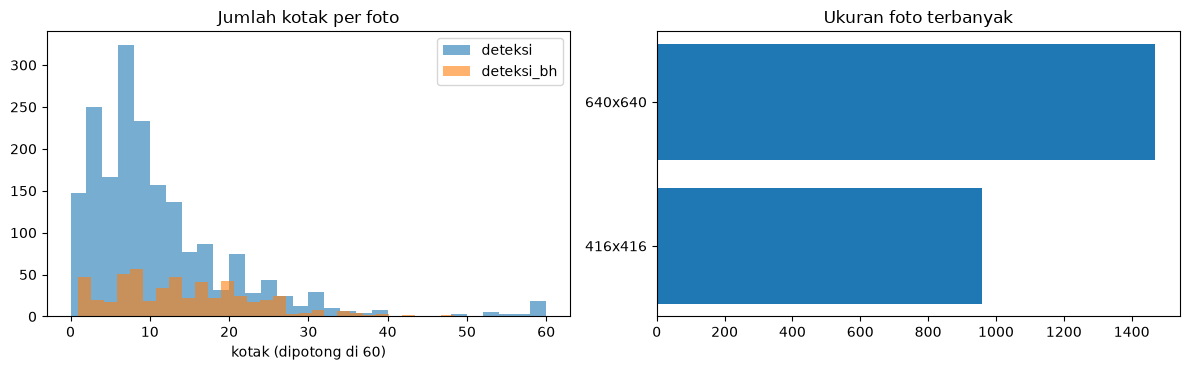

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for d in ('deteksi', 'deteksi_bh'):
    ax[0].hist(foto[foto.dataset == d].kotak.clip(upper=60), bins=30, alpha=0.6, label=d)
ax[0].set_title('Jumlah kotak per foto'); ax[0].set_xlabel('kotak (dipotong di 60)'); ax[0].legend()
uk = foto.groupby(['lebar', 'tinggi']).size().sort_values(ascending=False).head(8)
ax[1].barh([f'{w}x{h}' for w, h in uk.index], uk.values); ax[1].invert_yaxis(); ax[1].set_title('Ukuran foto terbanyak')
plt.tight_layout(); plt.show()

## 2. Ukuran kotak jerawat

              count   25%   50%   75%
dataset                              
deteksi     20159.0  17.4  27.1  39.4
deteksi_bh   7866.0  34.8  46.1  61.8
Kotak lebih kecil dari 16 px: 14%


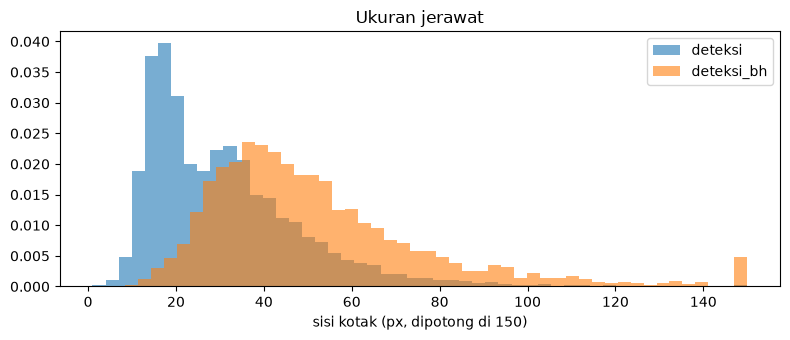

In [4]:
kotak['sisi_px'] = np.sqrt(kotak.w_px * kotak.h_px)
print(kotak.groupby('dataset').sisi_px.describe()[['count', '25%', '50%', '75%']].round(1).to_string())
print('Kotak lebih kecil dari 16 px:', f"{(kotak.sisi_px < 16).mean():.0%}")
fig, ax = plt.subplots(figsize=(8, 3.5))
for d in ('deteksi', 'deteksi_bh'):
    ax.hist(kotak[kotak.dataset == d].sisi_px.clip(upper=150), bins=50, alpha=0.6, label=d, density=True)
ax.set_xlabel('sisi kotak (px, dipotong di 150)'); ax.set_title('Ukuran jerawat'); ax.legend(); plt.tight_layout(); plt.show()

Jerawat sangat kecil dibanding foto (median 27 px di dataset lama dan 46 px di foto Blackheads), dan banyak jerawat berdekatan.
Ini yang membuat deteksi sulit, terutama Blackheads yang hanya titik kecil.

## 3. Contoh foto dengan kotak label

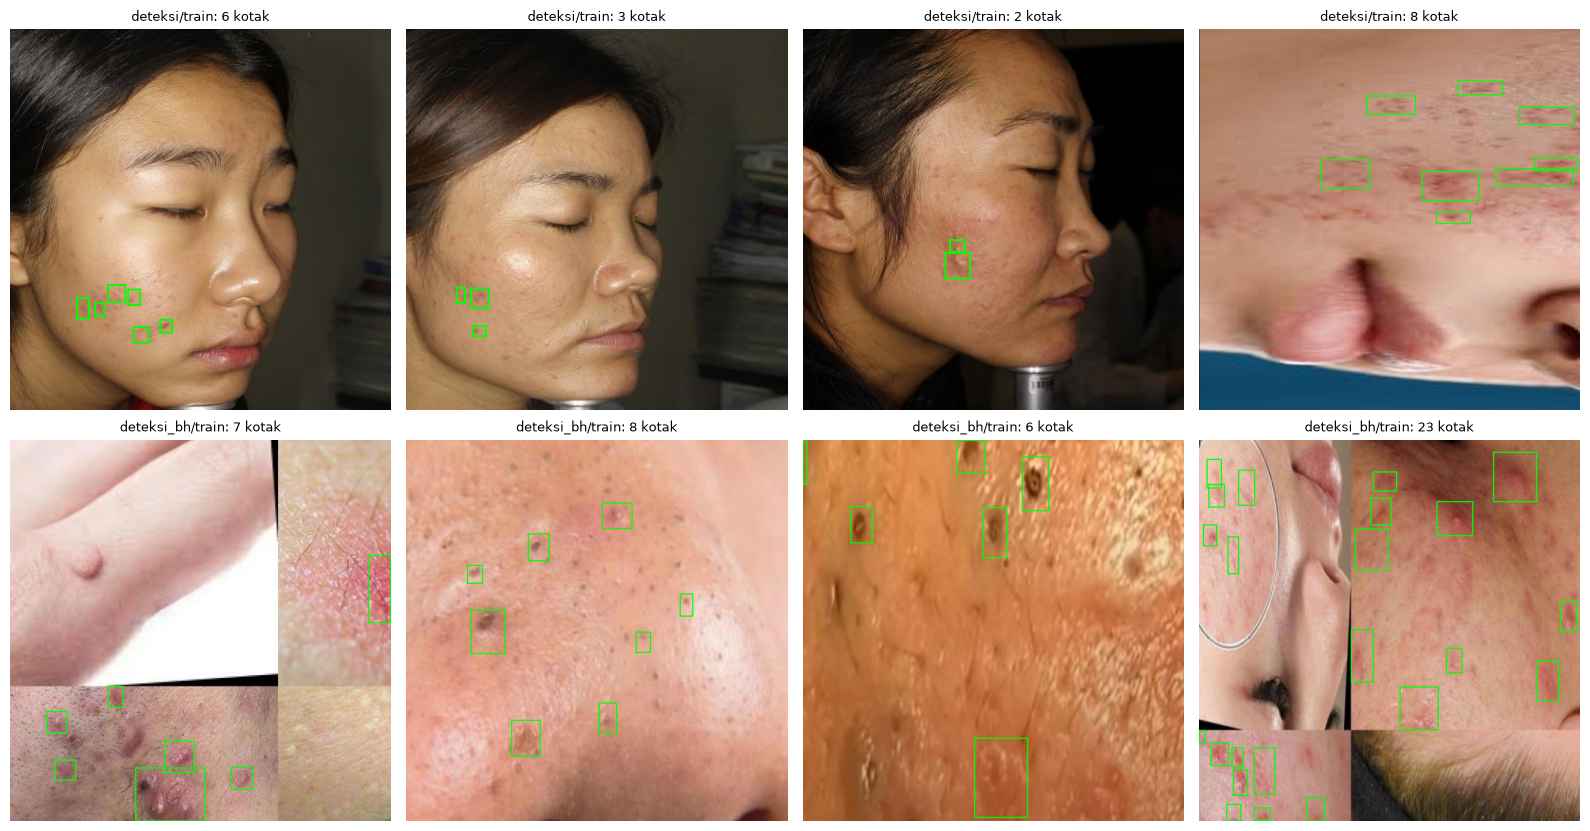

In [5]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))
for a, (d, s) in zip(ax.flat, [('deteksi', 'train')] * 4 + [('deteksi_bh', 'train')] * 4):
    g = rng.choice(foto[(foto.dataset == d) & (foto.bagian == s)].foto.values)
    im = Image.open(g).convert('RGB'); W, H = im.size; dr = ImageDraw.Draw(im)
    lb = baca_label(DATA / d / s / 'labels' / (g.stem + '.txt'))
    for x, y, w, h in lb:
        dr.rectangle(((x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H), outline=(0, 255, 0), width=2)
    a.imshow(im); a.axis('off'); a.set_title(f'{d}/{s}: {len(lb)} kotak', fontsize=9)
plt.tight_layout(); plt.show()

## 4. Jenis jerawat di test baru
Test baru punya catatan jenis asli tiap kotak (dari "Acne new data"), dipakai untuk menghitung recall per jenis di notebook evaluasi.

In [6]:
jenis = json.load(open(DATA / 'deteksi_bh' / 'jenis_asli_test.json'))
hitung = Counter(k[0] for v in jenis.values() for k in v)
print(pd.Series(hitung).sort_values(ascending=False).to_string())

Blackhead    448
Papular      300
Acne         187
Purulent     129
Whitehead    122
Cystic        40


## Kesimpulan EDA
1. Foto kecil (paling besar 640 px, banyak 416 px) dan jerawatnya kecil.
2. Banyak jerawat per foto (rata-rata belasan), sering berdempetan.
3. Blackheads adalah jenis terbanyak di test baru dan paling sulit, karena itu ditambahkan foto Blackheads ke train.